In [1]:
# ============================================================
# 1. Imports
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor
)

In [2]:
# ============================================================
# 2. Load CLV Excel dataset
# ============================================================

DATA_PATH = Path("osmos_clv_dataset.xlsx")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Put osmos_clv_dataset.xlsx in the same folder as this notebook."
    )

customers = pd.read_excel(DATA_PATH, sheet_name="Customers")
transactions = pd.read_excel(DATA_PATH, sheet_name="Transactions")
df_clv = pd.read_excel(DATA_PATH, sheet_name="CLV_Training_Table")

print("Customers:", customers.shape)
print("Transactions:", transactions.shape)
print("CLV training table:", df_clv.shape)

df_clv.head()

Customers: (7000, 19)
Transactions: (124226, 11)
CLV training table: (7000, 33)


,customer_id,recency_days,frequency_obs,total_spent_obs_mad,total_profit_obs_mad,avg_order_value_obs_mad,avg_profit_per_order_obs_mad,customer_age_days,purchase_interval_mean_days,purchase_interval_std_days,...,churn_risk_score,social_sentiment_avg,complaint_count_90d,review_score_avg,transaction_count_total,transaction_count_obs,transaction_count_future,clv_amount_mad,clv_score,clv_segment
0,CUST-06669,166,12,3324.90,1019.36,277.075000,84.946667,171,15.090909,13.179185,...,59,1.3,0,3.3,17,12,5,390.49,48,Medium Future Value
1,CUST-02080,152,19,7274.15,1816.66,382.850000,95.613684,168,8.444444,6.801576,...,69,1.4,0,4.8,21,19,2,140.48,32,Medium Future Value
2,CUST-03820,169,13,2290.42,786.40,176.186154,60.492308,170,14.083333,19.142805,...,22,3.2,0,4.7,19,13,6,564.93,56,High Future Value
3,CUST-00343,175,47,27128.65,8688.09,577.205319,184.852979,179,3.804348,4.693350,...,30,4.3,0,2.4,80,47,33,6816.95,97,Very High Future Value
4,CUST-05467,162,14,49099.67,13583.51,3507.119286,970.250714,179,12.461538,14.694757,...,12,3.7,1,3.7,18,14,4,1757.58,79,Very High Future Value


In [3]:
# ============================================================
# 3. Quick dataset validation
# ============================================================

print("CLV columns:")
print(df_clv.columns.tolist())

print("\nMissing values:")
display(df_clv.isna().sum().sort_values(ascending=False).head(20))

print("\nTarget description:")
display(df_clv["clv_amount_mad"].describe())

print("\nCLV segment distribution:")
display(df_clv["clv_segment"].value_counts())

print("\nObservation frequency description:")
display(df_clv["frequency_obs"].describe())

CLV columns:
['customer_id', 'recency_days', 'frequency_obs', 'total_spent_obs_mad', 'total_profit_obs_mad', 'avg_order_value_obs_mad', 'avg_profit_per_order_obs_mad', 'customer_age_days', 'purchase_interval_mean_days', 'purchase_interval_std_days', 'discount_rate_mean', 'return_rate', 'preferred_category', 'region', 'source_channel', 'segment', 'persona', 'age_group', 'preferred_device', 'marketing_consent', 'price_sensitivity', 'income_power_score', 'behavioral_engagement_score', 'churn_risk_score', 'social_sentiment_avg', 'complaint_count_90d', 'review_score_avg', 'transaction_count_total', 'transaction_count_obs', 'transaction_count_future', 'clv_amount_mad', 'clv_score', 'clv_segment']

Missing values:


customer_id                     0
recency_days                    0
frequency_obs                   0
total_spent_obs_mad             0
total_profit_obs_mad            0
avg_order_value_obs_mad         0
avg_profit_per_order_obs_mad    0
customer_age_days               0
purchase_interval_mean_days     0
purchase_interval_std_days      0
discount_rate_mean              0
return_rate                     0
preferred_category              0
region                          0
source_channel                  0
segment                         0
persona                         0
age_group                       0
preferred_device                0
marketing_consent               0
dtype: int64


Target description:


count     7000.000000
mean      1340.621783
std       2596.158863
min       -758.580000
25%         75.975000
50%        435.535000
75%       1474.227500
max      44068.150000
Name: clv_amount_mad, dtype: float64


CLV segment distribution:


clv_segment
Medium Future Value       1750
High Future Value         1750
Very High Future Value    1750
Low Future Value          1750
Name: count, dtype: int64


Observation frequency description:


count    7000.000000
mean       12.852143
std        14.102811
min         0.000000
25%         4.000000
50%         8.000000
75%        14.000000
max        78.000000
Name: frequency_obs, dtype: float64

In [4]:
# ============================================================
# 4. Clean CLV training table
# ============================================================

df_model = df_clv.copy()

# Remove clients with no purchase history in the observation window
df_model = df_model[df_model["frequency_obs"] > 0].copy()

# Make sure target is numeric
df_model["clv_amount_mad"] = pd.to_numeric(
    df_model["clv_amount_mad"],
    errors="coerce"
)

df_model = df_model.dropna(subset=["clv_amount_mad"])

print("Rows after cleaning:", df_model.shape)

display(df_model[[
    "customer_id",
    "frequency_obs",
    "total_spent_obs_mad",
    "avg_order_value_obs_mad",
    "clv_amount_mad",
    "clv_score",
    "clv_segment"
]].head())

Rows after cleaning: (6905, 33)


,customer_id,frequency_obs,total_spent_obs_mad,avg_order_value_obs_mad,clv_amount_mad,clv_score,clv_segment
0,CUST-06669,12,3324.90,277.075000,390.49,48,Medium Future Value
1,CUST-02080,19,7274.15,382.850000,140.48,32,Medium Future Value
2,CUST-03820,13,2290.42,176.186154,564.93,56,High Future Value
3,CUST-00343,47,27128.65,577.205319,6816.95,97,Very High Future Value
4,CUST-05467,14,49099.67,3507.119286,1757.58,79,Very High Future Value


In [5]:
# ============================================================
# 5. Define features and target
# ============================================================

TARGET = "clv_amount_mad"

# Important:
# Remove future/leakage columns:
# - clv_amount_mad is the target
# - clv_score and clv_segment are derived from the target
# - transaction_count_future is future information
# - transaction_count_total includes future transactions
# - customer_id is only an identifier

cols_to_drop = [
    "customer_id",
    "clv_amount_mad",
    "clv_score",
    "clv_segment",
    "transaction_count_future",
    "transaction_count_total"
]

X = df_model.drop(columns=cols_to_drop, errors="ignore")
y = df_model[TARGET]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFeatures used:")
print(X.columns.tolist())
print(len(X.columns.tolist()))

X shape: (6905, 27)
y shape: (6905,)

Features used:
['recency_days', 'frequency_obs', 'total_spent_obs_mad', 'total_profit_obs_mad', 'avg_order_value_obs_mad', 'avg_profit_per_order_obs_mad', 'customer_age_days', 'purchase_interval_mean_days', 'purchase_interval_std_days', 'discount_rate_mean', 'return_rate', 'preferred_category', 'region', 'source_channel', 'segment', 'persona', 'age_group', 'preferred_device', 'marketing_consent', 'price_sensitivity', 'income_power_score', 'behavioral_engagement_score', 'churn_risk_score', 'social_sentiment_avg', 'complaint_count_90d', 'review_score_avg', 'transaction_count_obs']
27


In [6]:
# ============================================================
# 6. Detect numeric and categorical columns
# ============================================================

numeric_cols = X.select_dtypes(include=["int64", "float64", "int32", "float32"]).columns.tolist()
categorical_cols = X.select_dtypes(include=["object", "bool", "category"]).columns.tolist()

print("Numeric columns:", len(numeric_cols))
print(numeric_cols)

print("\nCategorical columns:", len(categorical_cols))
print(categorical_cols)

Numeric columns: 19
['recency_days', 'frequency_obs', 'total_spent_obs_mad', 'total_profit_obs_mad', 'avg_order_value_obs_mad', 'avg_profit_per_order_obs_mad', 'customer_age_days', 'purchase_interval_mean_days', 'purchase_interval_std_days', 'discount_rate_mean', 'return_rate', 'price_sensitivity', 'income_power_score', 'behavioral_engagement_score', 'churn_risk_score', 'social_sentiment_avg', 'complaint_count_90d', 'review_score_avg', 'transaction_count_obs']

Categorical columns: 8
['preferred_category', 'region', 'source_channel', 'segment', 'persona', 'age_group', 'preferred_device', 'marketing_consent']


In [7]:
# ============================================================
# 7. Preprocessing pipeline
# ============================================================

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_cols),
        ("cat", categorical_transformer, categorical_cols)
    ]
)

In [8]:
# ============================================================
# 8. Train/test split
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (5524, 27)
Test: (1381, 27)


In [11]:
# ============================================================
# 9. Define regression models
# ============================================================

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso,
    ElasticNet,
    HuberRegressor,
    BayesianRidge
)

from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.kernel_ridge import KernelRidge

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor,
    AdaBoostRegressor,
    BaggingRegressor,
    VotingRegressor,
    StackingRegressor
)

# ============================================================
# Base models
# ============================================================

models = {
    "Linear Regression": LinearRegression(),

    "Ridge Regression": Ridge(
        alpha=1.0,
        random_state=42
    ),

    "Lasso Regression": Lasso(
        alpha=0.001,
        max_iter=5000,
        random_state=42
    ),

    "ElasticNet": ElasticNet(
        alpha=0.001,
        l1_ratio=0.5,
        max_iter=5000,
        random_state=42
    ),

    "Bayesian Ridge": BayesianRidge(),

    "Huber Regressor": HuberRegressor(
        max_iter=1000
    ),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=10,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42
    ),

    "KNN Regressor": KNeighborsRegressor(
        n_neighbors=10,
        weights="distance"
    ),

    "SVR": SVR(
        kernel="rbf",
        C=10,
        epsilon=0.1
    ),

    "Kernel Ridge": KernelRidge(
        alpha=1.0,
        kernel="rbf"
    ),

    "MLP Regressor": MLPRegressor(
        hidden_layer_sizes=(128, 64),
        activation="relu",
        solver="adam",
        max_iter=500,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        max_depth=None,
        min_samples_split=4,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=300,
        max_depth=None,
        min_samples_split=4,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ),

    "Hist Gradient Boosting": HistGradientBoostingRegressor(
        max_iter=300,
        learning_rate=0.05,
        random_state=42
    ),

    "AdaBoost": AdaBoostRegressor(
        n_estimators=200,
        learning_rate=0.05,
        random_state=42
    ),

    "Bagging Regressor": BaggingRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )
}

# ============================================================
# Optional advanced boosting models
# Install if needed:
# pip install xgboost lightgbm catboost
# ============================================================

try:
    from xgboost import XGBRegressor

    models["XGBoost"] = XGBRegressor(
        n_estimators=600,
        learning_rate=0.03,
        max_depth=5,
        subsample=0.9,
        colsample_bytree=0.9,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

    models["XGBoost Tuned"] = XGBRegressor(
        n_estimators=800,
        learning_rate=0.02,
        max_depth=4,
        min_child_weight=3,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_alpha=0.1,
        reg_lambda=1.0,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

except ImportError:
    print("XGBoost not installed. Install with: pip install xgboost")


try:
    from lightgbm import LGBMRegressor

    models["LightGBM"] = LGBMRegressor(
        n_estimators=600,
        learning_rate=0.03,
        num_leaves=31,
        max_depth=-1,
        random_state=42,
        n_jobs=-1,
        verbose=-1
    )

    models["LightGBM Tuned"] = LGBMRegressor(
        n_estimators=800,
        learning_rate=0.02,
        num_leaves=40,
        min_child_samples=20,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_alpha=0.1,
        reg_lambda=1.0,
        random_state=42,
        n_jobs=-1,
        verbose=-1
    )

except ImportError:
    print("LightGBM not installed. Install with: pip install lightgbm")


try:
    from catboost import CatBoostRegressor

    models["CatBoost"] = CatBoostRegressor(
        iterations=600,
        learning_rate=0.03,
        depth=6,
        loss_function="RMSE",
        verbose=False,
        random_state=42
    )

    models["CatBoost Tuned"] = CatBoostRegressor(
        iterations=800,
        learning_rate=0.02,
        depth=7,
        l2_leaf_reg=5,
        loss_function="RMSE",
        verbose=False,
        random_state=42
    )

except ImportError:
    print("CatBoost not installed. Install with: pip install catboost")


# ============================================================
# Ensemble models
# ============================================================

models["Voting Regressor"] = VotingRegressor(
    estimators=[
        ("hgb", HistGradientBoostingRegressor(
            max_iter=300,
            learning_rate=0.05,
            random_state=42
        )),
        ("gb", GradientBoostingRegressor(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=3,
            random_state=42
        )),
        ("rf", RandomForestRegressor(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

models["Stacking Regressor"] = StackingRegressor(
    estimators=[
        ("hgb", HistGradientBoostingRegressor(
            max_iter=300,
            learning_rate=0.05,
            random_state=42
        )),
        ("gb", GradientBoostingRegressor(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=3,
            random_state=42
        )),
        ("rf", RandomForestRegressor(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        ))
    ],
    final_estimator=Ridge(alpha=1.0),
    n_jobs=-1
)

print("Total models to train:", len(models))
print(list(models.keys()))

Total models to train: 25
['Linear Regression', 'Ridge Regression', 'Lasso Regression', 'ElasticNet', 'Bayesian Ridge', 'Huber Regressor', 'Decision Tree', 'KNN Regressor', 'SVR', 'Kernel Ridge', 'MLP Regressor', 'Random Forest', 'Extra Trees', 'Gradient Boosting', 'Hist Gradient Boosting', 'AdaBoost', 'Bagging Regressor', 'XGBoost', 'XGBoost Tuned', 'LightGBM', 'LightGBM Tuned', 'CatBoost', 'CatBoost Tuned', 'Voting Regressor', 'Stacking Regressor']


In [12]:
# ============================================================
# 10. Train and compare CLV regression models
# ============================================================

results = []
trained_models = {}
failed_models = {}

for model_name, regressor in models.items():
    print(f"\nTraining: {model_name}")

    model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", regressor)
    ])

    try:
        start_time = time.time()

        model.fit(X_train, y_train)

        training_time = time.time() - start_time

        y_pred = model.predict(X_test)

        mae = mean_absolute_error(y_test, y_pred)
        rmse = np.sqrt(mean_squared_error(y_test, y_pred))
        r2 = r2_score(y_test, y_pred)

        results.append({
            "model": model_name,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2,
            "training_time_seconds": training_time
        })

        trained_models[model_name] = model

        print(f"Done: {model_name}")
        print(f"MAE: {mae:.2f} | RMSE: {rmse:.2f} | R2: {r2:.4f} | Time: {training_time:.2f}s")

    except Exception as e:
        failed_models[model_name] = str(e)
        print(f"Failed: {model_name}")
        print("Reason:", e)


# ============================================================
# Results table
# ============================================================

results_df = pd.DataFrame(results).sort_values(by="MAE", ascending=True)

display(results_df)

best_model_name = results_df.iloc[0]["model"]
best_clv_model = trained_models[best_model_name]

print("\nBest CLV model:", best_model_name)
print("Best MAE:", round(results_df.iloc[0]["MAE"], 2))
print("Best RMSE:", round(results_df.iloc[0]["RMSE"], 2))
print("Best R2:", round(results_df.iloc[0]["R2"], 4))


# ============================================================
# Failed models summary
# ============================================================

if len(failed_models) > 0:
    print("\nFailed models:")
    for name, error in failed_models.items():
        print(f"- {name}: {error}")
else:
    print("\nNo failed models.")


Training: Linear Regression
Done: Linear Regression
MAE: 1013.68 | RMSE: 1827.68 | R2: 0.4960 | Time: 0.11s

Training: Ridge Regression
Done: Ridge Regression
MAE: 1013.47 | RMSE: 1827.55 | R2: 0.4961 | Time: 0.05s

Training: Lasso Regression
Done: Lasso Regression
MAE: 1013.68 | RMSE: 1827.68 | R2: 0.4960 | Time: 1.70s

Training: ElasticNet
Done: ElasticNet
MAE: 1013.13 | RMSE: 1827.35 | R2: 0.4962 | Time: 2.37s

Training: Bayesian Ridge
Done: Bayesian Ridge
MAE: 1008.81 | RMSE: 1825.59 | R2: 0.4971 | Time: 0.07s

Training: Huber Regressor
Done: Huber Regressor
MAE: 873.51 | RMSE: 1868.78 | R2: 0.4731 | Time: 0.46s

Training: Decision Tree
Done: Decision Tree
MAE: 783.01 | RMSE: 1620.42 | R2: 0.6038 | Time: 0.18s

Training: KNN Regressor
Done: KNN Regressor
MAE: 784.20 | RMSE: 1621.25 | R2: 0.6034 | Time: 0.08s

Training: SVR
Done: SVR
MAE: 999.62 | RMSE: 2406.99 | R2: 0.1259 | Time: 2.74s

Training: Kernel Ridge
Done: Kernel Ridge
MAE: 649.19 | RMSE: 1331.67 | R2: 0.7324 | Time: 2.2

,model,MAE,RMSE,R2,training_time_seconds
20,LightGBM Tuned,541.048040,1143.815414,0.802600,1.121462
19,LightGBM,546.443199,1146.468831,0.801683,0.848835
14,Hist Gradient Boosting,550.488202,1113.334126,0.812981,1.337990
17,XGBoost,550.788785,1114.212121,0.812685,1.089579
24,Stacking Regressor,561.437869,1147.845658,0.801206,54.207582
18,XGBoost Tuned,564.996182,1137.140500,0.804897,0.978179
21,CatBoost,578.026322,1158.099206,0.797639,2.342405
22,CatBoost Tuned,594.042933,1202.084774,0.781975,3.823954
23,Voting Regressor,596.784464,1197.752178,0.783544,19.294315
10,MLP Regressor,605.207166,1265.989777,0.758178,40.425419



Best CLV model: LightGBM Tuned
Best MAE: 541.05
Best RMSE: 1143.82
Best R2: 0.8026

No failed models.


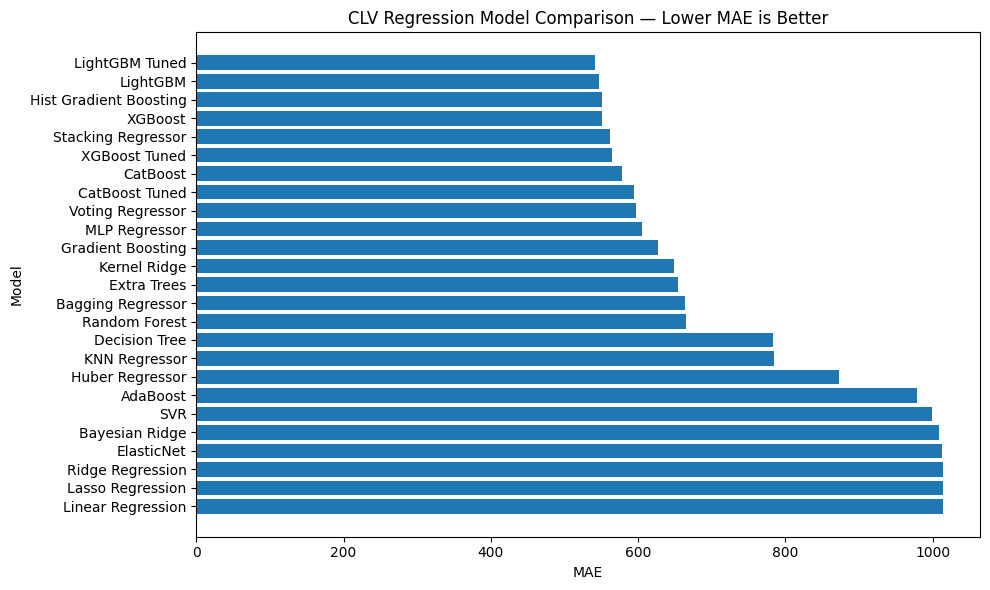

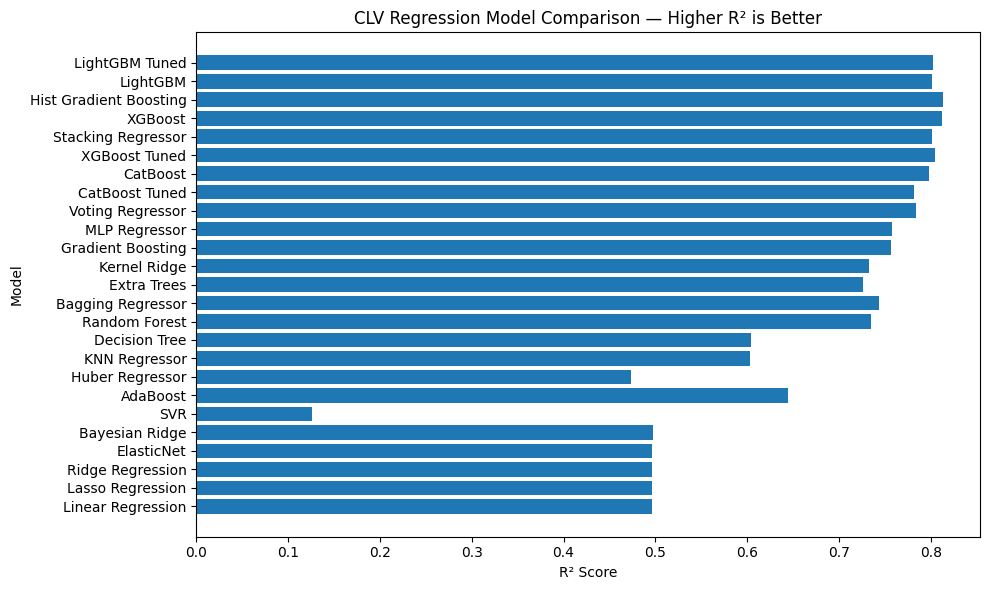

In [13]:
# ============================================================
# 11. Plot model comparison
# ============================================================

plt.figure(figsize=(10, 6))
plt.barh(results_df["model"], results_df["MAE"])
plt.gca().invert_yaxis()
plt.xlabel("MAE")
plt.ylabel("Model")
plt.title("CLV Regression Model Comparison — Lower MAE is Better")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
plt.barh(results_df["model"], results_df["R2"])
plt.gca().invert_yaxis()
plt.xlabel("R² Score")
plt.ylabel("Model")
plt.title("CLV Regression Model Comparison — Higher R² is Better")
plt.tight_layout()
plt.show()

In [14]:
# ============================================================
# 12. Best model evaluation
# ============================================================

y_pred_best = best_clv_model.predict(X_test)

mae_best = mean_absolute_error(y_test, y_pred_best)
rmse_best = np.sqrt(mean_squared_error(y_test, y_pred_best))
r2_best = r2_score(y_test, y_pred_best)

print("Best model:", best_model_name)
print("MAE:", mae_best)
print("RMSE:", rmse_best)
print("R²:", r2_best)

comparison_df = pd.DataFrame({
    "actual_clv_amount_mad": y_test.values,
    "predicted_clv_amount_mad": y_pred_best
})

comparison_df["error"] = (
    comparison_df["actual_clv_amount_mad"] -
    comparison_df["predicted_clv_amount_mad"]
)

comparison_df.head(10)

Best model: LightGBM Tuned
MAE: 541.0480395120294
RMSE: 1143.8154143461616
R²: 0.8025997652565028


,actual_clv_amount_mad,predicted_clv_amount_mad,error
0,266.04,22.248716,243.791284
1,5292.14,5125.032907,167.107093
2,1743.15,1452.972625,290.177375
3,1148.67,540.766741,607.903259
4,1738.65,3354.359370,-1615.709370
5,450.45,329.673357,120.776643
6,0.00,-62.107344,62.107344
7,792.16,363.330567,428.829433
8,0.00,57.708331,-57.708331
9,330.61,509.010532,-178.400532


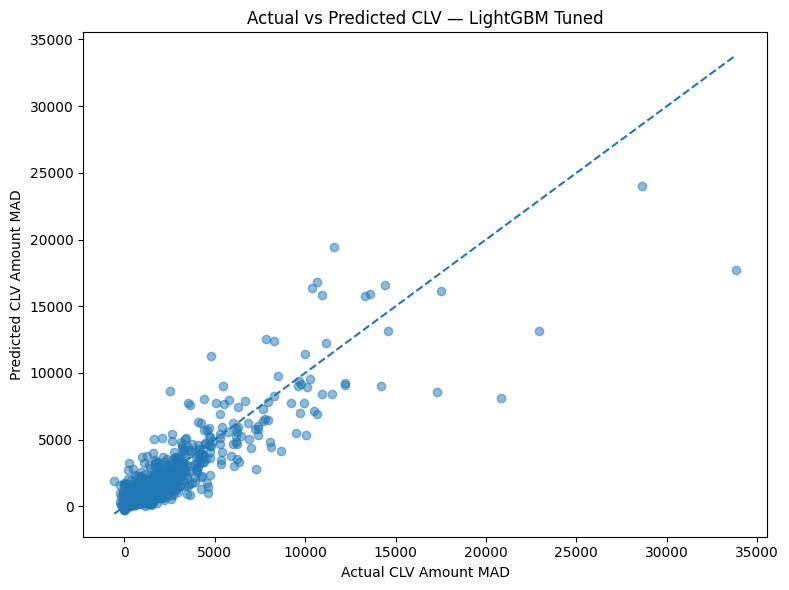

In [15]:
# ============================================================
# 13. Actual vs Predicted CLV
# ============================================================

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_best, alpha=0.5)

min_val = min(y_test.min(), y_pred_best.min())
max_val = max(y_test.max(), y_pred_best.max())

plt.plot([min_val, max_val], [min_val, max_val], linestyle="--")

plt.xlabel("Actual CLV Amount MAD")
plt.ylabel("Predicted CLV Amount MAD")
plt.title(f"Actual vs Predicted CLV — {best_model_name}")
plt.tight_layout()
plt.show()

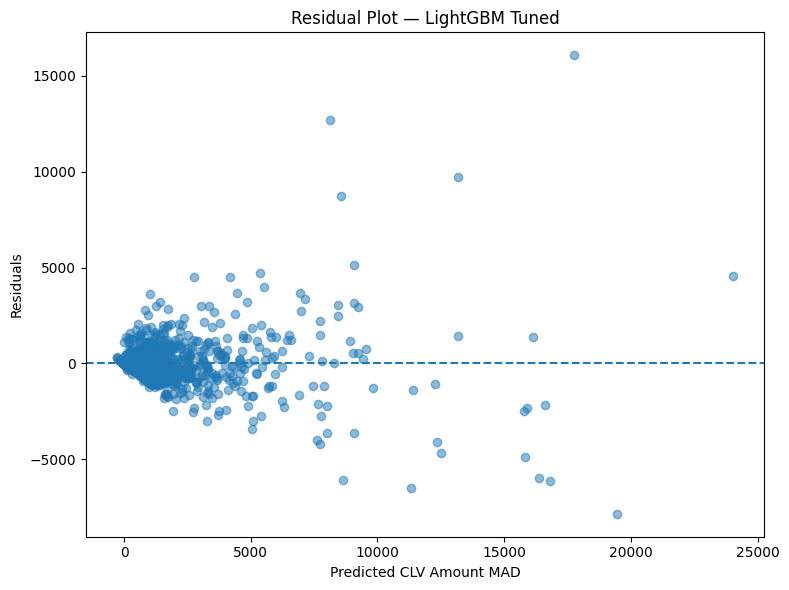

In [16]:
# ============================================================
# 14. Residual plot
# ============================================================

residuals = y_test - y_pred_best

plt.figure(figsize=(8, 6))
plt.scatter(y_pred_best, residuals, alpha=0.5)
plt.axhline(0, linestyle="--")

plt.xlabel("Predicted CLV Amount MAD")
plt.ylabel("Residuals")
plt.title(f"Residual Plot — {best_model_name}")
plt.tight_layout()
plt.show()

,feature,importance
13,num__behavioral_engagement_score,3731
14,num__churn_risk_score,2934
12,num__income_power_score,2462
2,num__total_spent_obs_mad,2301
3,num__total_profit_obs_mad,2061
4,num__avg_order_value_obs_mad,1935
5,num__avg_profit_per_order_obs_mad,1746
1,num__frequency_obs,1620
9,num__discount_rate_mean,1085
11,num__price_sensitivity,1084


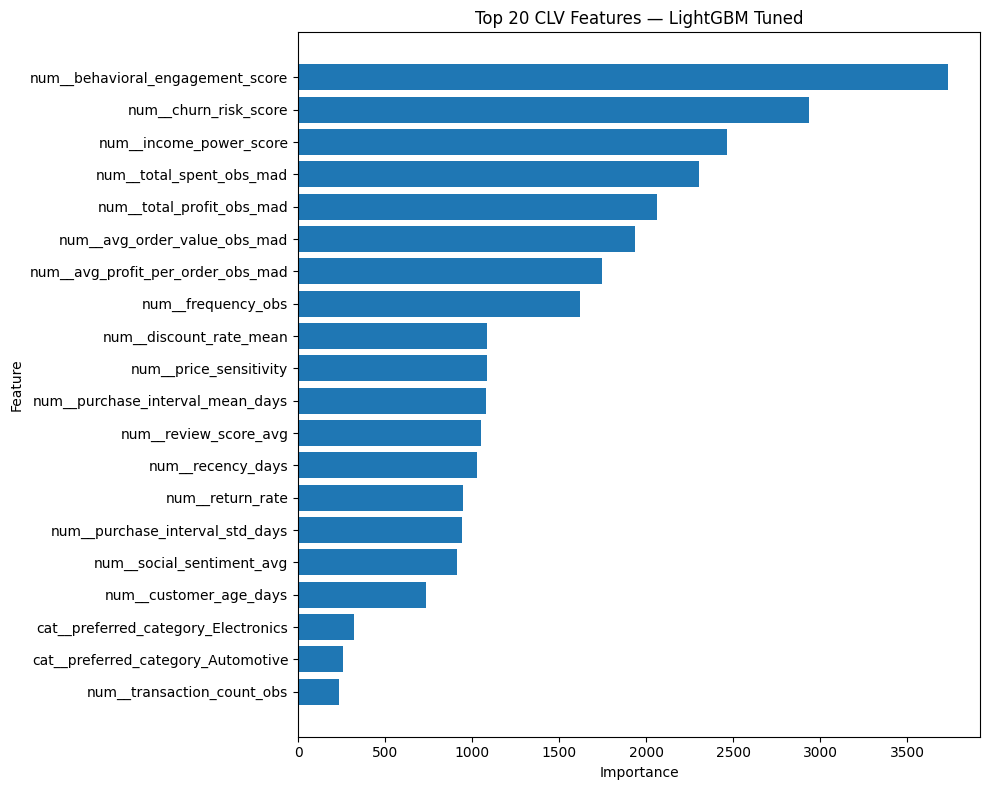

In [17]:
# ============================================================
# 15. Feature importance for tree-based models
# ============================================================

regressor = best_clv_model.named_steps["regressor"]

if hasattr(regressor, "feature_importances_"):

    feature_names = best_clv_model.named_steps["preprocessor"].get_feature_names_out()

    importance_df = pd.DataFrame({
        "feature": feature_names,
        "importance": regressor.feature_importances_
    }).sort_values(by="importance", ascending=False)

    display(importance_df.head(30))

    top_features = importance_df.head(20)

    plt.figure(figsize=(10, 8))
    plt.barh(top_features["feature"], top_features["importance"])
    plt.gca().invert_yaxis()
    plt.xlabel("Importance")
    plt.ylabel("Feature")
    plt.title(f"Top 20 CLV Features — {best_model_name}")
    plt.tight_layout()
    plt.show()

else:
    print(f"{best_model_name} does not provide direct feature_importances_.")

In [18]:
# ============================================================
# 16. Create predicted CLV score and segment
# ============================================================

# Predict CLV for all cleaned clients
df_predictions = df_model.copy()

X_all = df_predictions.drop(columns=cols_to_drop, errors="ignore")

df_predictions["predicted_clv_amount_mad"] = best_clv_model.predict(X_all)

# Optional: for admin display, avoid negative predicted CLV
df_predictions["predicted_clv_amount_mad_display"] = (
    df_predictions["predicted_clv_amount_mad"].clip(lower=0)
)

# Convert predicted CLV amount to score 0-100 using percentile rank
df_predictions["predicted_clv_score"] = (
    df_predictions["predicted_clv_amount_mad_display"].rank(pct=True) * 100
).round(2)

# Segment based on predicted CLV score
df_predictions["predicted_clv_segment"] = pd.cut(
    df_predictions["predicted_clv_score"],
    bins=[0, 25, 50, 75, 100],
    labels=[
        "Low Future Value",
        "Medium Future Value",
        "High Future Value",
        "Very High Future Value"
    ],
    include_lowest=True
)

display(df_predictions[[
    "customer_id",
    "clv_amount_mad",
    "clv_score",
    "clv_segment",
    "predicted_clv_amount_mad",
    "predicted_clv_score",
    "predicted_clv_segment"
]].head(20))

,customer_id,clv_amount_mad,clv_score,clv_segment,predicted_clv_amount_mad,predicted_clv_score,predicted_clv_segment
0,CUST-06669,390.49,48,Medium Future Value,409.823581,45.27,Medium Future Value
1,CUST-02080,140.48,32,Medium Future Value,228.689152,30.99,Medium Future Value
2,CUST-03820,564.93,56,High Future Value,461.416361,48.11,Medium Future Value
3,CUST-00343,6816.95,97,Very High Future Value,6866.882239,96.44,Very High Future Value
4,CUST-05467,1757.58,79,Very High Future Value,2973.733812,88.25,Very High Future Value
5,CUST-01592,0.00,2,Low Future Value,-18.381904,2.09,Low Future Value
6,CUST-01393,217.04,38,Medium Future Value,212.863066,29.34,Medium Future Value
7,CUST-00683,420.32,49,Medium Future Value,306.967609,37.89,Medium Future Value
8,CUST-04566,1638.08,77,Very High Future Value,2031.515970,81.87,Very High Future Value
9,CUST-06300,0.00,2,Low Future Value,58.807303,11.44,Low Future Value


,feature,importance,std
21,behavioral_engagement_score,960.857180,26.015831
22,churn_risk_score,243.994628,13.687436
1,frequency_obs,214.348441,10.765780
3,total_profit_obs_mad,180.929199,12.033723
2,total_spent_obs_mad,136.877007,4.430001
20,income_power_score,114.187755,9.719105
11,preferred_category,65.237731,2.871071
7,purchase_interval_mean_days,56.430213,4.514641
4,avg_order_value_obs_mad,52.712951,6.801802
5,avg_profit_per_order_obs_mad,36.919399,4.483748


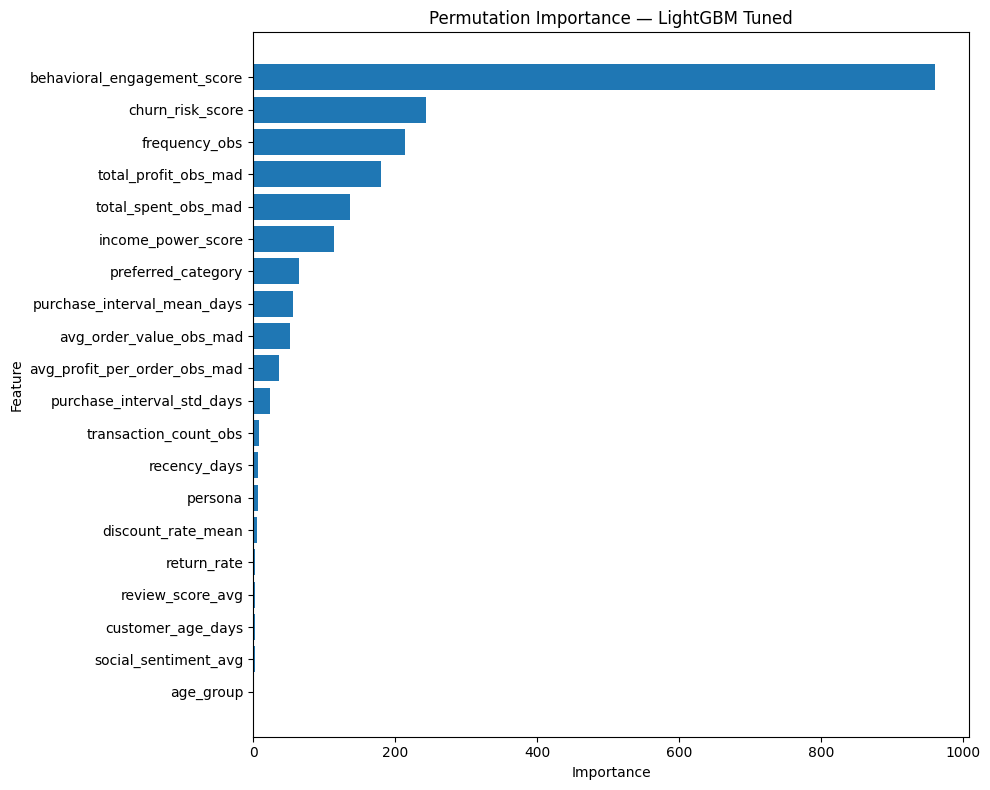

In [19]:
# ============================================================
# Permutation importance — model-agnostic importance
# ============================================================

from sklearn.inspection import permutation_importance

perm_result = permutation_importance(
    best_clv_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

perm_importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance": perm_result.importances_mean,
    "std": perm_result.importances_std
}).sort_values(by="importance", ascending=False)

display(perm_importance_df.head(20))

top_perm = perm_importance_df.head(20)

plt.figure(figsize=(10, 8))
plt.barh(top_perm["feature"], top_perm["importance"])
plt.gca().invert_yaxis()
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title(f"Permutation Importance — {best_model_name}")
plt.tight_layout()
plt.show()

In [20]:
# ============================================================
# Convert predicted CLV amount into CLV segments
# ============================================================

y_pred_best = best_clv_model.predict(X_test)

segment_eval_df = pd.DataFrame({
    "actual_clv_amount_mad": y_test.values,
    "predicted_clv_amount_mad": y_pred_best
})

# Avoid negative values for display/segmentation
segment_eval_df["predicted_clv_amount_mad_display"] = (
    segment_eval_df["predicted_clv_amount_mad"].clip(lower=0)
)

# True CLV score based on actual CLV
segment_eval_df["actual_clv_score"] = (
    segment_eval_df["actual_clv_amount_mad"].rank(pct=True) * 100
).round(2)

# Predicted CLV score based on predicted CLV
segment_eval_df["predicted_clv_score"] = (
    segment_eval_df["predicted_clv_amount_mad_display"].rank(pct=True) * 100
).round(2)

# Convert scores to segments
labels = [
    "Low Future Value",
    "Medium Future Value",
    "High Future Value",
    "Very High Future Value"
]

segment_eval_df["actual_clv_segment"] = pd.cut(
    segment_eval_df["actual_clv_score"],
    bins=[0, 25, 50, 75, 100],
    labels=labels,
    include_lowest=True
)

segment_eval_df["predicted_clv_segment"] = pd.cut(
    segment_eval_df["predicted_clv_score"],
    bins=[0, 25, 50, 75, 100],
    labels=labels,
    include_lowest=True
)

display(segment_eval_df.head())

,actual_clv_amount_mad,predicted_clv_amount_mad,predicted_clv_amount_mad_display,actual_clv_score,predicted_clv_score,actual_clv_segment,predicted_clv_segment
0,266.04,22.248716,22.248716,40.84,7.10,Medium Future Value,Low Future Value
1,5292.14,5125.032907,5125.032907,94.50,94.50,Very High Future Value,Very High Future Value
2,1743.15,1452.972625,1452.972625,77.41,74.44,Very High Future Value,High Future Value
3,1148.67,540.766741,540.766741,70.24,51.27,High Future Value,High Future Value
4,1738.65,3354.359370,3354.359370,77.34,89.72,Very High Future Value,Very High Future Value


<Figure size 1000x700 with 0 Axes>

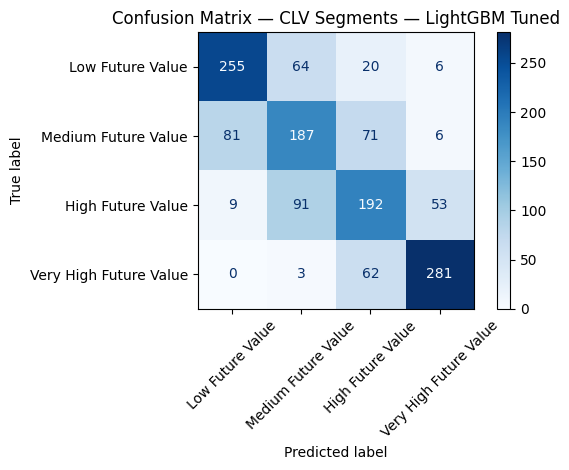

Classification report for CLV segments:
                        precision    recall  f1-score   support

      Low Future Value       0.74      0.74      0.74       345
   Medium Future Value       0.54      0.54      0.54       345
     High Future Value       0.56      0.56      0.56       345
Very High Future Value       0.81      0.81      0.81       346

              accuracy                           0.66      1381
             macro avg       0.66      0.66      0.66      1381
          weighted avg       0.66      0.66      0.66      1381



In [21]:
# ============================================================
# Confusion matrix — CLV segments
# ============================================================

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

cm = confusion_matrix(
    segment_eval_df["actual_clv_segment"],
    segment_eval_df["predicted_clv_segment"],
    labels=labels
)

plt.figure(figsize=(10, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

disp.plot(
    xticks_rotation=45,
    cmap="Blues",
    values_format="d"
)

plt.title(f"Confusion Matrix — CLV Segments — {best_model_name}")
plt.tight_layout()
plt.show()

print("Classification report for CLV segments:")
print(classification_report(
    segment_eval_df["actual_clv_segment"],
    segment_eval_df["predicted_clv_segment"],
    labels=labels
))

In [ ]:
# # ============================================================
# # Export CLV model artifact
# # ============================================================

# import joblib
# import numpy as np
# import pandas as pd
# from datetime import datetime

# # Predict on all available training rows to create reference distribution
# X_all = df_model.drop(columns=cols_to_drop, errors="ignore")
# y_all_pred = best_clv_model.predict(X_all)

# # For admin display, negative CLV can be clipped only for scoring/segmentation
# y_all_pred_display = np.clip(y_all_pred, 0, None)

# # Save reference values to calculate percentile-based CLV score later
# clv_reference_values = pd.Series(y_all_pred_display).sort_values().values

# # CLV segment labels
# clv_segment_labels = [
#     "Low Future Value",
#     "Medium Future Value",
#     "High Future Value",
#     "Very High Future Value"
# ]

# # Full artifact for the Streamlit interface
# clv_model_artifact = {
#     "model": best_clv_model,
#     "best_model_name": best_model_name,
#     "feature_columns": list(X.columns),
#     "target": "clv_amount_mad",
#     "numeric_cols": numeric_cols,
#     "categorical_cols": categorical_cols,
#     "results": results_df,
#     "clv_reference_values": clv_reference_values,
#     "clv_segment_labels": clv_segment_labels,
#     "export_date": datetime.now().strftime("%Y-%m-%d %H:%M:%S")
# }

# # Save artifact
# joblib.dump(clv_model_artifact, "osmos_best_clv_model_artifact.pkl")

# print("CLV model exported successfully.")
# print("Best model:", best_model_name)
# print("Saved as: osmos_best_clv_model_artifact.pkl")
# print("Number of features:", len(X.columns))

CLV model exported successfully.
Best model: Hist Gradient Boosting
Saved as: osmos_best_clv_model_artifact.pkl
Number of features: 27


In [ ]:
# # ============================================================
# # Test exported CLV model artifact
# # ============================================================

# import joblib
# import numpy as np
# import pandas as pd

# artifact = joblib.load("osmos_best_clv_model_artifact.pkl")

# loaded_model = artifact["model"]
# feature_columns = artifact["feature_columns"]
# reference_values = artifact["clv_reference_values"]
# segment_labels = artifact["clv_segment_labels"]

# # Take one sample
# sample = X_test.iloc[[0]].copy()

# # Align columns exactly
# sample = sample[feature_columns]

# # Predict CLV amount
# predicted_clv_amount = loaded_model.predict(sample)[0]

# # Clip only for display/score
# predicted_clv_display = max(predicted_clv_amount, 0)

# # Convert predicted CLV amount to percentile score
# clv_score = (
#     np.searchsorted(reference_values, predicted_clv_display, side="right")
#     / len(reference_values)
# ) * 100

# clv_score = round(clv_score, 2)

# # Convert score to segment
# if clv_score <= 25:
#     clv_segment = "Low Future Value"
# elif clv_score <= 50:
#     clv_segment = "Medium Future Value"
# elif clv_score <= 75:
#     clv_segment = "High Future Value"
# else:
#     clv_segment = "Very High Future Value"

# print("Loaded model:", artifact["best_model_name"])
# print("Predicted CLV amount MAD:", round(predicted_clv_amount, 2))
# print("CLV score:", clv_score)
# print("CLV segment:", clv_segment)

Loaded model: Hist Gradient Boosting
Predicted CLV amount MAD: 129.87
CLV score: 19.15
CLV segment: Low Future Value
